# Домашнее задание по теме «Стохастический градиентный спуск»

В этом задании с помощью библиотеки Torch ты будешь реализовывать стохастические методы. В качестве модели возьмём логистическую регрессию, а в качестве данных — [датасет](https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/binary/a9a) из библиотеки LIBSVM.

## Основная часть [10 баллов]

#### Импорт библиотек

In [1]:
import os
import time
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_svmlight_file
from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, TensorDataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn
from torch.optim import Optimizer

import torchvision
from torchvision.datasets.utils import download_url
import torchvision.transforms as transforms

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

### Стохастические методы [7 баллов]

#### Задача 1 [1 балл]

Реализуй класс `LIBSVM` для работы с данными во время обучения и валидации.

<!-- 1. С помощью функции `load_svmlight_file` распарси файл, лежащий в директории `file_dir`.
2. После этого преобразуй дата-матрицу $X$ в формат Tensor (воспользуйся функцией `torch.from_numpy`) и выполни нормализацию данных по второй норме для каждой строки.
3. Вектор меток $y$ также нужно преобразовать к формату Tensor, а также привести метки к значениям $0$ и $1$.
4. Раздели данные на обучающую и тестовую выборки, используя `train_test_split` с параметром `random_state=57`.
5. Преобразованные данные нужно сохранить в атрибутах `self.train_dataset` и `self.test_dataset` как элементы класса TensorDataset (достаточно подать преобразованные тензоры $X$ и $y$ в него). -->

Допиши метод инициализации класса:
1. распарси файл в директории `file_dir` с помощью функции `load_svmlight_file`;
2. преобразуй дата-матрицу $X$ в формат Tensor с помощью функции `torch.from_numpy` и выполни нормализацию данных по второй норме для каждой строки;
3. приведи вектор меток $y$ к формату Tensor и переведи значения меток в $0$ и $1$;
4. раздели данные на обучающую и тестовую выборки с помощью функции `train_test_split` с параметром `random_state=57`;
5. сохрани преобразованные данные в атрибутах `self.train_dataset` и `self.test_dataset` как элементы класса TensorDataset (достаточно подать преобразованные тензоры $X$ и $y$ в него).

In [3]:
DOWNLOAD_LINKS = {'a9a': 'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/binary/a9a'}

class LIBSVM(Dataset):
    def __init__(self, root, dataset_name, download=True, test_size=0.2, random_state=57):
        download_link = DOWNLOAD_LINKS[dataset_name]
        target = os.path.basename(download_link)
        file_dir = os.path.join(root, target)

        if not os.path.exists(file_dir):
            if download:
                download_url(download_link, root)
            else:
                raise FileNotFoundError(f"{file_dir} не существует")

        # Твой код здесь
        X_sparse, y_downloaded = load_svmlight_file(file_dir)
        X_tensor = torch.from_numpy(X_sparse.toarray()).float()
        norms = torch.norm(X_tensor, p=2, dim=1, keepdim=True)
        X_normalized = X_tensor / norms.clamp_min(1e-12)
        y_norm = (torch.from_numpy(y_downloaded).float() + 1) / 2

        X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_norm, test_size=test_size, random_state=random_state)

        self.train_dataset = TensorDataset(X_train, y_train)
        self.test_dataset = TensorDataset(X_test, y_test)

In [4]:
test = LIBSVM(root='.', dataset_name='a9a')

100%|██████████| 2.33M/2.33M [00:01<00:00, 2.04MB/s]


#### Задача 2 [1 балл]

Создай модель `LogisticRegression`, состоящую из блока [`nn.Linear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html) без `bias` с функцией активации [`F.sigmoid`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.sigmoid.html).

_Указание:_ необходимо выдавать одно значение — вероятность, что метка принадлежит первому классу.

In [5]:
class LogisticRegression(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
        self.sigmoid = F.sigmoid
        

    def forward(self, x):
        return self.sigmoid(self.linear(x))

        # Твой код здесь


#### Задача 3 [2 балла]

Допиши код **стохастического градиентного спуска (SGD)** с возможностью задать коэффициент моментума (параметр `momentum`) и коэффициент $L_2$-регуляризации (параметр `weight_decay`).



<br>

**Псевдокод алгоритма**

---

_Инициализация:_

- Начальная точка $x^0 \in \mathbb{R}^d$.
- Начальный буфер $v^0 \in \mathbb{R}^d$.
- Размер шага $\{ \gamma_k \}_{k=0} > 0$.
- Моментумы $\{ \tau_k \}_{k=0} > 0$.
- Коэффициент $L_2$-регуляризации $\lambda \geq 0$.

---

$k$_-я итерация_:

1. Вычислить градиент и применить $L_2$-регуляризацию:

$$
g^{k + 1} = \nabla f \left(x^k\right) + \lambda x^k.
$$

2. Обновить буфер моментума:

$$
v^{k+1} = \tau_k v^{k} + g^{k+1}.
$$

3. Обновить параметры:

$$
x^{k+1} = x^k - \gamma_k v^{k+1}.
$$

In [6]:
class SGD(Optimizer):
    """
    Реализация стохастического градиентного спуска с моментумом и L2-регуляризацией.

    Параметры:
        params (Iterable): итерируемый объект параметров для оптимизации или словарь.
        lr (float): скорость обучения.
        momentum (float): коэффициент моментума.
        weight_decay (float): коэффициент L2-регуляризации.
    """

    def __init__(self, params, lr=1e-3, momentum=0, weight_decay=0):

        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super(SGD, self).__init__(params, defaults)

    def step(self, closure=None):
        """
        Выполняет один шаг оптимизатора.

        Параметры:
            closure (Сallable): замыкание, которое пересчитывает модель и возвращает loss.
        """

        loss = closure() if closure is not None else None

        for group in self.param_groups:
            lr = group['lr']
            momentum = group['momentum']
            weight_decay = group['weight_decay']

            for p in group['params']:
                if p.grad is None:
                    continue

                # Твой код здесь
                with torch.no_grad():
                    grad = p.grad

                    if weight_decay:
                        grad = grad.add(p, alpha=weight_decay)

                    if momentum:
                        state = self.state[p]
                        if "momentum_buffer" not in state:
                            state["momentum_buffer"] = grad.clone()
                        else:
                            state["momentum_buffer"].mul_(momentum).add_(grad)
                        grad = state["momentum_buffer"]

                    p.add_(grad, alpha=-lr)


        return loss

#### Задача 4 [2 балла]

Реализуй метод `trainer`, который выполняет обучение и валидацию модели на протяжении заданного числа эпох. Допиши обёрточные функции `train` и `test` для каждой эпохи обучения.

In [7]:
def trainer(num_epochs, batch_size, model_class, criterion, optimizer_class,
            optimizer_params, dataset, device='cuda' if torch.cuda.is_available() else 'cpu'):
    """
    Универсальная функция для обучения моделей PyTorch.

    Параметры:
        num_epochs (int): количество эпох обучения.
        batch_size (int): размер батча для DataLoader.
        model_class (nn.Module): класс модели.
        criterion (nn.Module): функция потерь.
        optimizer_class (optim.Optimizer): класс оптимизатора.
        optimizer_params (dict): параметры оптимизатора.
        dataset (Dataset): объект датасета.
        device (str): устройство для вычислений.

    Возвращает:
        tuple: (train_losses, train_accuracies, test_losses, test_accuracies)
            train_losses: значения потерь на обучении.
            train_accuracies: значения accuracy на обучении.
            test_losses: значения потерь на тесте.
            test_accuracies: значения accuracy на тесте.
    """
    # Инициализация DataLoader
    train_loader = DataLoader(dataset.train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(dataset.test_dataset, batch_size=batch_size, shuffle=False)

    # Определение размерности входа
    input_dim = dataset.train_dataset[0][0].shape[0]

    # Инициализация модели
    model = model_class(input_dim=input_dim).to(device)
    optimizer = optimizer_class(model.parameters(), **optimizer_params)

    # Метрики
    train_losses = []
    train_accuracies = []
    test_losses = []
    test_accuracies = []

    # Функции для train/test одной эпохи
    def train_epoch(epoch):
        model.train()
        total_loss = 0.0
        correct = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            pred = model(x).squeeze(-1)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += ((pred >= 0.5) == y.bool()).sum().item()

        n = len(train_loader.dataset)
        return total_loss / n, 100 * correct / n

    def test_epoch(epoch):
        model.eval()
        total_loss = 0.0
        correct = 0
    
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
    
                pred = model(x).squeeze(-1)
                loss = criterion(pred, y)
    
                total_loss += loss.item()
                correct += ((pred >= 0.5) == y.bool()).sum().item()
    
        n = len(test_loader.dataset)
        return total_loss / n, 100 * correct / n

    # Основной цикл обучения
    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_epoch(epoch)
        test_loss, test_acc = test_epoch(epoch)

        # Сохранение метрик
        train_losses.append(train_loss)
        train_accuracies.append(train_acc)
        test_losses.append(test_loss)
        test_accuracies.append(test_acc)

        # Вывод статистики
        epoch_time = time.time() - start_time
        print(f'Epoch {epoch + 1} / {num_epochs} | '
              f'Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | '
              f'Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}% | '
              f'Time: {epoch_time:.2f}s')

    return train_losses, train_accuracies, test_losses, test_accuracies

#### Задача 5 [1 балл]

- Запусти обучение с конфигурацией ниже.

In [8]:
config = {
    'num_epochs': 50,
    'batch_size': 120,
    'model_class': LogisticRegression,
    'criterion': nn.BCELoss(reduction='sum'),
    'optimizer_class': SGD,
    'optimizer_params': {'lr': 1e-3, 'momentum': 0.9, 'weight_decay': 1e-6},
    'dataset': LIBSVM(root='./data', dataset_name='a9a'),
    'device' : 'cpu'
}

# Запуск обучения
train_loss, train_acc, test_loss, test_acc = trainer(**config)

100%|██████████| 2.33M/2.33M [00:00<00:00, 3.36MB/s]


Epoch 1 / 50 | Train Loss: 0.4205 | Train Acc: 79.93% | Test Loss: 0.3764 | Test Acc: 82.56% | Time: 0.46s
Epoch 2 / 50 | Train Loss: 0.3556 | Train Acc: 83.54% | Test Loss: 0.3583 | Test Acc: 83.10% | Time: 0.35s
Epoch 3 / 50 | Train Loss: 0.3434 | Train Acc: 84.02% | Test Loss: 0.3504 | Test Acc: 83.37% | Time: 0.37s
Epoch 4 / 50 | Train Loss: 0.3375 | Train Acc: 84.30% | Test Loss: 0.3463 | Test Acc: 83.33% | Time: 0.40s
Epoch 5 / 50 | Train Loss: 0.3337 | Train Acc: 84.49% | Test Loss: 0.3434 | Test Acc: 83.45% | Time: 0.42s
Epoch 6 / 50 | Train Loss: 0.3316 | Train Acc: 84.50% | Test Loss: 0.3414 | Test Acc: 83.51% | Time: 0.37s
Epoch 7 / 50 | Train Loss: 0.3298 | Train Acc: 84.65% | Test Loss: 0.3404 | Test Acc: 83.69% | Time: 0.35s
Epoch 8 / 50 | Train Loss: 0.3285 | Train Acc: 84.64% | Test Loss: 0.3396 | Test Acc: 83.65% | Time: 0.36s
Epoch 9 / 50 | Train Loss: 0.3275 | Train Acc: 84.79% | Test Loss: 0.3383 | Test Acc: 83.77% | Time: 0.41s
Epoch 10 / 50 | Train Loss: 0.3269 | 

- Построй сравнительные графики значений функции потерь и значений метрики `accuracy` в зависимости от числа эпох.

In [9]:
X_train, y_train = config["dataset"].train_dataset.tensors
print("Форма X:", X_train.shape)
print("Доля классов:", torch.unique(y_train, return_counts=True))

Форма X: torch.Size([26048, 123])
Доля классов: (tensor([0., 1.]), tensor([19768,  6280]))


Epoch 1 / 50 | Train Loss: 0.4210 | Train Acc: 80.35% | Test Loss: 0.3759 | Test Acc: 82.56% | Time: 0.34s
Epoch 2 / 50 | Train Loss: 0.3556 | Train Acc: 83.50% | Test Loss: 0.3580 | Test Acc: 83.36% | Time: 0.34s
Epoch 3 / 50 | Train Loss: 0.3434 | Train Acc: 84.01% | Test Loss: 0.3507 | Test Acc: 83.37% | Time: 0.33s
Epoch 4 / 50 | Train Loss: 0.3373 | Train Acc: 84.27% | Test Loss: 0.3460 | Test Acc: 83.39% | Time: 0.34s
Epoch 5 / 50 | Train Loss: 0.3337 | Train Acc: 84.45% | Test Loss: 0.3442 | Test Acc: 83.63% | Time: 0.34s
Epoch 6 / 50 | Train Loss: 0.3313 | Train Acc: 84.52% | Test Loss: 0.3413 | Test Acc: 83.45% | Time: 0.34s
Epoch 7 / 50 | Train Loss: 0.3296 | Train Acc: 84.66% | Test Loss: 0.3403 | Test Acc: 83.80% | Time: 0.34s
Epoch 8 / 50 | Train Loss: 0.3288 | Train Acc: 84.61% | Test Loss: 0.3396 | Test Acc: 83.62% | Time: 0.35s
Epoch 9 / 50 | Train Loss: 0.3277 | Train Acc: 84.68% | Test Loss: 0.3382 | Test Acc: 83.77% | Time: 0.34s
Epoch 10 / 50 | Train Loss: 0.3272 | 

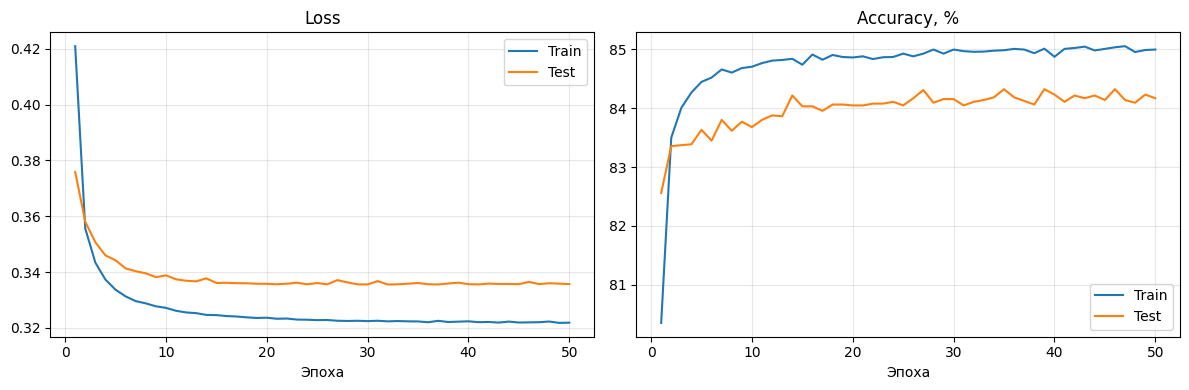

In [10]:
# Твой код здесь
# Твой код здесь
train_loss, train_acc, test_loss, test_acc = trainer(**config)
epochs = range(1, len(train_loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, train_loss, label="Train")
axes[0].plot(epochs, test_loss, label="Test")
axes[0].set_title("Loss")
axes[0].set_xlabel("Эпоха")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, train_acc, label="Train")
axes[1].plot(epochs, test_acc, label="Test")
axes[1].set_title("Accuracy, %")
axes[1].set_xlabel("Эпоха")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Влияния размера батча на обучение модели [3 балла]

В заданиях выше можно заметить, что даже простая модель быстро достигает высокой точности на табличных данных — для этого достаточно одной эпохи. Однако в реальных задачах данные сложнее, и важную роль в качестве прогнозов модели играет выбор гиперпараметров. В следующих заданиях мы посмотрим, как размер батча влияет на качество обучения и скорость сходимости модели на примере датасета [`FashionMNIST`](https://www.kaggle.com/datasets/zalando-research/fashionmnist).

FashionMNIST состоит из картинок размером 28 × 28, каждая из которых принадлежит одному из 10 классов.

In [11]:
class FashionMNIST(Dataset):
    def __init__(self, root='.', download=True):
        transform = transforms.Compose([
            transforms.ToTensor()
        ])

        self.train_dataset = torchvision.datasets.FashionMNIST(
            root=root, train=True, download=download, transform=transform)
        self.test_dataset = torchvision.datasets.FashionMNIST(
            root=root, train=False, download=download, transform=transform)

In [12]:
FashionMNIST_dataset = FashionMNIST(root='.')

100%|██████████| 26.4M/26.4M [00:04<00:00, 6.41MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 100kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.66MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.2MB/s]


In [13]:
fashion_classes = (
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
)

def imshow_fashionmnist(img, ax=None, title=None):
    npimg = img.numpy().squeeze()  # (1, H, W) → (H, W)
    if ax is None:
        plt.imshow(npimg, cmap='gray')
        if title:
            plt.title(title)
        plt.axis('off')
    else:
        ax.imshow(npimg, cmap='gray')
        if title:
            ax.set_title(title)
        ax.axis('off')

def show_fashionmnist_samples(dataset, num_samples=20, rows=4, cols=5):
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), size=num_samples, replace=False)

    for idx, ax in zip(indices, axes):
        image, label = dataset[idx]
        imshow_fashionmnist(image, ax=ax, title=fashion_classes[label])

    for j in range(num_samples, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

Amount of train samples: 60000
Amount of test samples: 10000


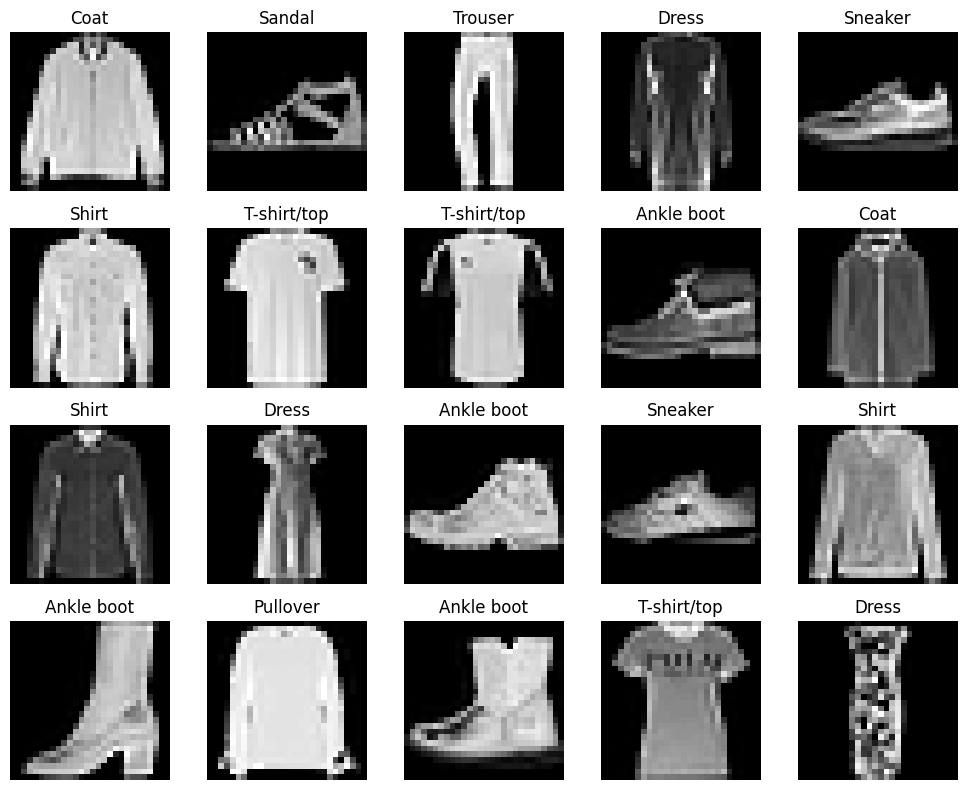

In [14]:
print(f"Amount of train samples: {len(FashionMNIST_dataset.train_dataset)}")
print(f"Amount of test samples: {len(FashionMNIST_dataset.test_dataset)}")

show_fashionmnist_samples(FashionMNIST_dataset.train_dataset)

#### Задача 6 [1 балл]

Логистическая регрессия недостаточно хорошо приближает распределение данных в датасете F-MNIST -- рассмотрим более глубокую нейронную сеть. Напиши реализацию **Multi-Layer Perceptron (MLP)**, применив функции из пакета `torch.nn` в такой последовательности:

1. [nn.Flatten()](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.flatten.Flatten.html#torch.nn.modules.flatten.Flatten),
2. [nn.Linear(input_size, hidden_size)](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html),
3. [nn.ReLU()](https://docs.pytorch.org/docs/stable/generated/torch.nn.ReLU.html),
4. [nn.Linear(hidden_size, num_classes)](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html).

In [15]:
class MLP(nn.Module):
    def __init__(self, input_size=28*28, hidden_size=256, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_h1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.linear_h2 = nn.Linear(hidden_size, num_classes)
        # Твой код здесь

    def forward(self, x):
        h1 = self.linear_h1(self.flatten(x))
        h2 = self.relu(h1)
        return self.linear_h2(h2)

        # Твой код здесь

#### Задача 7 [1 балла]

Модифицируй метод `trainer`, добавив поддержку многоклассовой классификации.

In [16]:
def trainer(num_epochs, batch_size, model_class, criterion, optimizer_class,
            optimizer_params, dataset, device='cuda' if torch.cuda.is_available() else 'cpu'):

    """
    Универсальная функция для обучения моделей PyTorch.

    Параметры:
        num_epochs (int): количество эпох обучения.
        batch_size (int): размер батча для DataLoader.
        model_class (nn.Module): класс модели.
        criterion (nn.Module): функция потерь.
        optimizer_class (optim.Optimizer): класс оптимизатора.
        optimizer_params (dict): параметры оптимизатора.
        dataset (Dataset): объект датасета.
        device (str): устройство для вычислений.

    Возвращает:
        tuple: (train_losses, train_accuracies, test_losses, test_accuracies)
            train_losses: значения потерь на обучении.
            train_accuracies: значения accuracy на обучении.
            test_losses: значения потерь на тесте.
            test_accuracies: значения accuracy на тесте.
    """
    # Инициализация DataLoader
    train_loader = DataLoader(dataset.train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(dataset.test_dataset, batch_size=batch_size, shuffle=False)

    # Инициализация модели
    model = model_class().to(device)
    optimizer = optimizer_class(model.parameters(), **optimizer_params)

    # Метрики
    train_losses = []
    train_accuracies = []
    test_losses = []
    test_accuracies = []

    # Функции для train/test одной эпохи
    def train_epoch(epoch):
        model.train()
        total_loss = 0.0
        correct = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(dim=1)  == y).sum().item()

        n = len(train_loader.dataset)
        return total_loss / n, 100 * correct / n

    def test_epoch(epoch):
        model.eval()
        total_loss = 0.0
        correct = 0

        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)

                logits = model(x)
                loss = criterion(logits, y)

                total_loss += loss.item() * x.size(0)
                correct += (logits.argmax(dim=1) == y).sum().item()

        n = len(test_loader.dataset)
        return total_loss / n, 100 * correct / n

    # Основной цикл обучения
    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_epoch(epoch)
        test_loss, test_acc = test_epoch(epoch)

        # Сохранение метрик
        train_losses.append(train_loss)
        train_accuracies.append(train_acc)
        test_losses.append(test_loss)
        test_accuracies.append(test_acc)

        # Вывод статистики
        epoch_time = time.time() - start_time
        print(f'Epoch {epoch + 1} / {num_epochs} | '
              f'Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | '
              f'Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}% | '
              f'Time: {epoch_time:.2f}s')

    return train_losses, train_accuracies, test_losses, test_accuracies

#### Задача 8 [1 балл]

Исследуй влияние размера батча на качество модели. Построй сравнительные графики значений функции потерь и значений метрики `accuracy` в зависимости от размера батча — используй шаблон ниже.

In [17]:
batch_sizes = [32, 64, 128, 256]

base_lr = 1e-3

train_acc_list=[]
test_acc_list=[]
train_losses_list=[]
test_losses_list=[]
for idx, batch_size in enumerate(batch_sizes):
    print(f"\n=== Training with batch size: {batch_size} ===")
    config = {
        'num_epochs': 10,
        'model_class': MLP,
        'criterion': nn.CrossEntropyLoss(reduction='mean'),
        'optimizer_class': SGD,
        'optimizer_params': {
            'lr': base_lr * np.sqrt(batch_size / 32),
            'momentum': 0.8,
            'weight_decay': 1e-4,
        },
        'dataset': FashionMNIST(),
        'device': 'cuda' if torch.cuda.is_available() else 'cpu',
        'batch_size': batch_size
    }

    train_loss, train_acc, test_loss, test_acc = trainer(**config)

    # Твой код здесь
    train_losses_list.append(train_loss[-1])
    test_losses_list.append(test_loss[-1])
    train_acc_list.append(train_acc[-1])
    test_acc_list.append(test_acc[-1])



=== Training with batch size: 32 ===
Epoch 1 / 10 | Train Loss: 1.1223 | Train Acc: 66.64% | Test Loss: 0.7516 | Test Acc: 73.35% | Time: 11.25s
Epoch 2 / 10 | Train Loss: 0.6571 | Train Acc: 77.92% | Test Loss: 0.6192 | Test Acc: 78.38% | Time: 11.22s
Epoch 3 / 10 | Train Loss: 0.5668 | Train Acc: 80.90% | Test Loss: 0.5668 | Test Acc: 80.25% | Time: 11.02s
Epoch 4 / 10 | Train Loss: 0.5219 | Train Acc: 82.42% | Test Loss: 0.5299 | Test Acc: 81.73% | Time: 10.95s
Epoch 5 / 10 | Train Loss: 0.4945 | Train Acc: 83.16% | Test Loss: 0.5102 | Test Acc: 82.31% | Time: 11.03s
Epoch 6 / 10 | Train Loss: 0.4758 | Train Acc: 83.68% | Test Loss: 0.4966 | Test Acc: 82.54% | Time: 10.90s
Epoch 7 / 10 | Train Loss: 0.4620 | Train Acc: 84.01% | Test Loss: 0.4846 | Test Acc: 83.07% | Time: 11.00s
Epoch 8 / 10 | Train Loss: 0.4505 | Train Acc: 84.47% | Test Loss: 0.4747 | Test Acc: 83.40% | Time: 11.02s
Epoch 9 / 10 | Train Loss: 0.4412 | Train Acc: 84.78% | Test Loss: 0.4698 | Test Acc: 83.47% | Tim

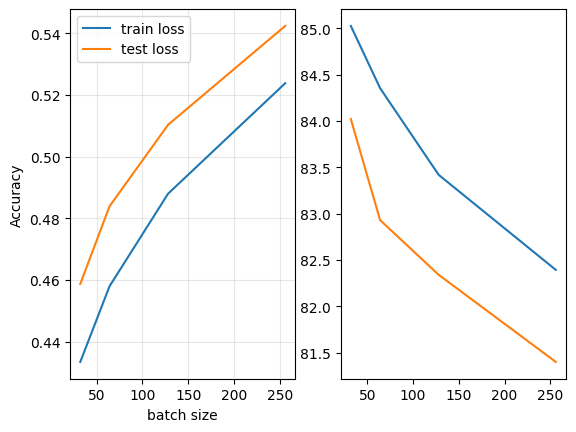

In [18]:
# Сравнительные графики
# Твой код здесь
fig, axes = plt.subplots(1, 2)
axes[0].plot(batch_sizes, train_losses_list, label='train loss')
axes[0].plot(batch_sizes, test_losses_list, label='test loss')
axes[0].legend()
axes[0].set_ylabel('loss')
axes[0].set_xlabel('batch size')
axes[0].grid(True, alpha=0.3)

axes[1].plot(batch_sizes, train_acc_list, label='train accuracy')
axes[1].plot(batch_sizes, test_acc_list, label='test accuracy')
axes[0].legend()
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('batch size')
axes[0].grid(True, alpha=0.3)

## Дополнительная часть [10 баллов]

#### Импорт библиотек

In [19]:
import warnings
warnings.filterwarnings("ignore")

from torch import optim
from torchvision.models import resnet18

### Обучение ResNet18

<!-- В данной части будут рассмотрены не столь "игрушечные" датасеты, а уже проверенный временем бенчмарк для компьютерного зрения — связка из датасета [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) (картинки 32 $\times$ 32, 50,000 сэмплов train, 10,000 сэмплов test, 10 классов) и нейронной архитектуры [ResNet18](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html). Так как курс посвящен оптимизации, то предлагается импортировать саму архитектуру (без непосредственной реализации) и работать с ней в парадигме "black-box" оптимизации — дан черный ящик в виде модели, хотим достичь наилучшего качества обучения. -->

В этой части мы поработаем с нейронной архитектурой [ResNet18](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html) на уже проверенном временем бенчмарке для компьютерного зрения — датасете [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) (картинки 32 $\times$ 32, в обучающей выборке 50,000 сэмплов, в тестовой 10,000 сэмплов, 10 классов).

Мы будем работать с нейронкой в парадигме "black-box" оптимизации — модель будет выступать в качестве "черного ящика": мы будем просто запрашивать значения по входу, не влезая в архитектуру. В результате мы хотим достичь наилучшего качества обучения.

In [20]:
class CIFAR10(Dataset):
    def __init__(self, root='.', download=True, normalize_mean=(0.5, 0.5, 0.5), normalize_std=(0.5, 0.5, 0.5)):
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(normalize_mean, normalize_std)
        ])

        self.train_dataset = torchvision.datasets.CIFAR10(
            root = root,
            train = True,
            transform = transform,
            download = download,
        )
        self.test_dataset = torchvision.datasets.CIFAR10(
            root = root,
            train = False,
            transform = transform,
            download = download,
        )

    def __getitem__(self, index):
        """
        Получение одного элемента из набора данных
        """
        return self.dataset.__getitem__(index)

    def __len__(self):
        """
        Количество элементов в наборе данных
        """
        return self.dataset.__len__()

In [21]:
CIFAR10_dataset = CIFAR10(root='.')

100%|██████████| 170M/170M [26:01<00:00, 109kB/s]  


In [22]:
classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

def imshow(img, ax=None, title=None):
    img = img / 2 + 0.5
    npimg = img.numpy()
    if ax is None:
        plt.imshow(np.transpose(npimg, (1, 2, 0)))
        if title:
            plt.title(title)
        plt.axis('off')
    else:
        ax.imshow(np.transpose(npimg, (1, 2, 0)))
        if title:
            ax.set_title(title)
        ax.axis('off')


def show_dataset_samples(dataset, num_samples=20, rows=4, cols=5):
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), size=num_samples, replace=False)

    for i, ax in enumerate(zip(indices, axes)):
        image, label = dataset[i]
        imshow(image, ax=ax[1], title=classes[label])

    for j in range(num_samples, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

Amount of train samples: 50000
Amount of test samples: 10000


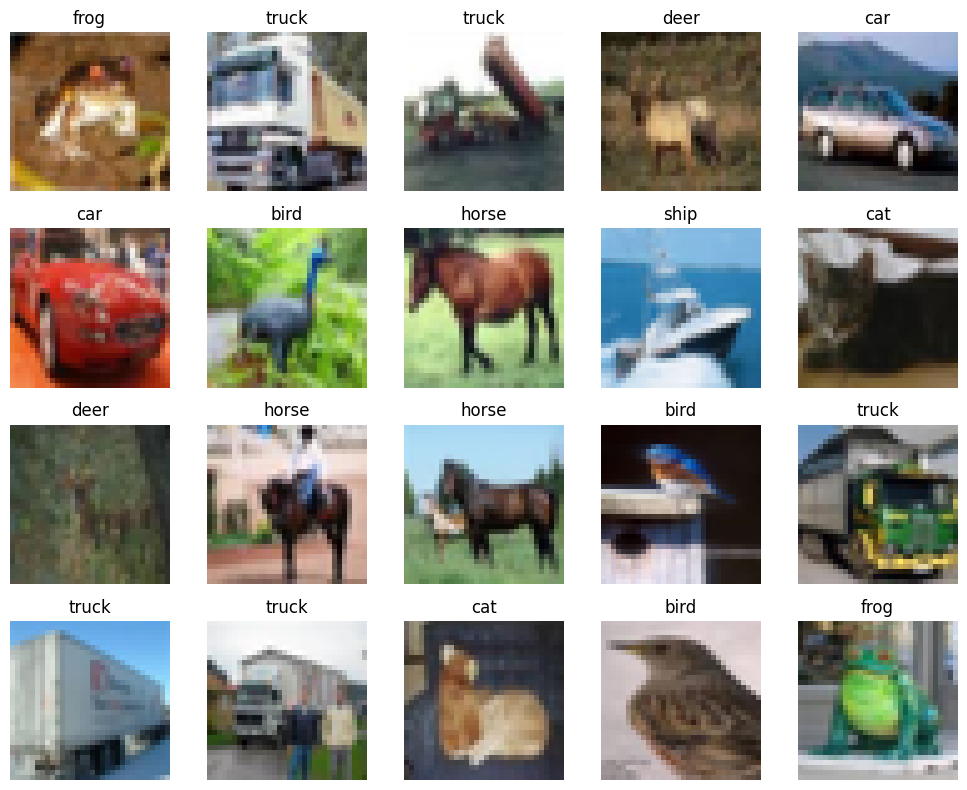

In [23]:
print(f"Amount of train samples: {len(CIFAR10_dataset.train_dataset)}")
print(f"Amount of test samples: {len(CIFAR10_dataset.test_dataset)}")

show_dataset_samples(CIFAR10_dataset.train_dataset)

<!-- Теперь проинициализируем сверточную модель `ResNet18` ([оригинальная статья](https://arxiv.org/abs/1512.03385), [реализация в torch](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)), для желающих разобраться, из каких слоев она состоит, добавлена функция `print_model_summary`, в которой перечислены все слои и число обучаемых параметров. -->

Теперь проинициализируем сверточную модель `ResNet18` ([оригинальная статья](https://arxiv.org/abs/1512.03385), [реализация в torch](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)).

Если хочешь разобраться в архитектуре модели, воспользуйся функцией `print_model_summary`: она выведет все слои и число обучаемых параметров.

In [24]:
# Число классов в датасете - 10
resnet = resnet18(weights=None, num_classes=10)

In [25]:
def print_model_summary(model, input_size):
    def register_hook(module):
        def hook(module, input, output):
            class_name = str(module.__class__).split(".")[-1].split("'")[0]
            module_idx = len(summary)

            m_key = f"{class_name}-{module_idx+1}"
            summary[m_key] = {
                "input_shape": list(input[0].size()),
                "output_shape": list(output.size()),
                "nb_params": sum(p.numel() for p in module.parameters())
            }

        if not isinstance(module, nn.Sequential) and not isinstance(module, nn.ModuleList) and module != model:
            hooks.append(module.register_forward_hook(hook))

    summary = {}
    hooks = []

    model.apply(register_hook)

    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size))

    for h in hooks:
        h.remove()

    print("----------------------------------------------------------------")

    line_new = "{:>20}  {:>25} {:>15}".format("Layer (type)", "Output Shape", "Param #")
    print(line_new)
    print("================================================================")

    total_params = 0

    for layer in summary:
        line_new = "{:>20}  {:>25} {:>15}".format(
            layer,
            str(summary[layer]["output_shape"]),
            "{0:,}".format(summary[layer]["nb_params"])
        )

        total_params += summary[layer]["nb_params"]

        print(line_new)

    print("================================================================")
    print(f"Total params: {total_params:,}")
    print("----------------------------------------------------------------")

# Входной размер картинки - (3, 32, 32), так как она RGB-шная
print_model_summary(resnet, (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [1, 64, 16, 16]           9,408
       BatchNorm2d-2            [1, 64, 16, 16]             128
              ReLU-3            [1, 64, 16, 16]               0
         MaxPool2d-4              [1, 64, 8, 8]               0
            Conv2d-5              [1, 64, 8, 8]          36,864
       BatchNorm2d-6              [1, 64, 8, 8]             128
              ReLU-7              [1, 64, 8, 8]               0
            Conv2d-8              [1, 64, 8, 8]          36,864
       BatchNorm2d-9              [1, 64, 8, 8]             128
             ReLU-10              [1, 64, 8, 8]               0
       BasicBlock-11              [1, 64, 8, 8]          73,984
           Conv2d-12              [1, 64, 8, 8]          36,864
      BatchNorm2d-13              [1, 64, 8, 8]             128
             ReLU-14              [1, 6

#### Задача 1 [5 баллов]

Рассмотрим несколько типов `lr_scheduler` — планировщика скорости обучения. Для них всех есть реализация в библиотеке `torch`.

- [`LambdaLR`](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LambdaLR.html):

$$
lr_{\text{epoch} + 1} = lr_\text{base} \cdot \lambda(\text{epoch} + 1)
$$

2) [`ExponentialLR`](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ExponentialLR.html):

$$
lr_{\text{epoch} + 1} = \gamma \cdot lr_\text{epoch}
$$

3) [`ReduceLROnPlateau`](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html):

    Шаг уменьшается на фактор при достижении плато в функции ошибок.

4) [`CosineAnnealingLR`](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html):

$$
lr_{\text{epoch} + 1} = \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})
    \left(1 + \cos \left(\frac{\pi (\text{epoch} + 1)}{T_{\max}}\right)\right)
$$

5) [`LinearLR`](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LinearLR.html):

$$
lr_{\text{epoch} + 1} = lr_\text{base} \cdot \left(\alpha + \left(1 - \alpha \right) \left(1 - \frac{\text{epoch} + 1}{T_{\max}}\right) \right)
$$

Функция `get_lr_schedule` возвращает список значений learning rate планировщика на каждой итерации.

In [26]:
def get_lr_schedule(model_class, optimizer_class, optimizer_params, scheduler_class, scheduler_params,
                    num_epochs=100, dummy_loss=None):
    """
    Возвращает список значений learning rate для заданного планировщика.

    Параметры:
        model_class (nn.Module): Модель
        optimizer_class (optim.Optimizer): Оптимизатор
        optimizer_params (dict): Параметры оптимизатора
        scheduler_class (optim.lr_scheduler): Планировщик скорости обучения
        scheduler_params (dict): Параметры планировщика
        num_epochs (int): Количество эпох для симуляции
        dummy_loss (list or None): Список значений потерь для ReduceLROnPlateau

    Возвращает:
        lrs (list): Список learning rate на каждой итерации
    """

    model = model_class()
    optimizer = optimizer_class(model.parameters(), **optimizer_params)
    scheduler = scheduler_class(optimizer, **scheduler_params)

    lrs = []

    for i in range(num_epochs):
        if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
            loss = dummy_loss[i] if dummy_loss is not None else 1.0
            scheduler.step(loss)
        else:
            scheduler.step()

        lrs.append(optimizer.param_groups[0]['lr'])

    return lrs

<!-- Изобрази поведение от номера эпохи `lr_scheduler`: `ExponentialLR`, `ReduceLROnPlateau`, `CosineAnnealingLR`, `LinearLR`. -->

- Изобрази поведение `lr_scheduler` от номера эпохи для `ExponentialLR`, `ReduceLROnPlateau`, `CosineAnnealingLR` и `LinearLR`. *Указание*: используй готовые реализации в `torch`.

In [27]:
# Простая модель
class DummyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(10, 2)

    def forward(self, x):
        return self.linear(x)

In [28]:
num_epochs = 100
dummy_losses = [1.0 / (i + 1) for i in range(num_epochs - 30)] + [0.0001 for j in range(30)]


lr_exponential = get_lr_schedule(
    model_class=lambda: torch.nn.Linear(1, 1),
    optimizer_class=torch.optim.SGD,
    optimizer_params={"lr": 0.1},
    scheduler_class=torch.optim.lr_scheduler.ExponentialLR,
    scheduler_params={"gamma": 0.93},
    num_epochs=num_epochs
)

lr_plateau = get_lr_schedule(
    model_class=lambda: torch.nn.Linear(1, 1),
    optimizer_class=torch.optim.SGD,
    optimizer_params={"lr": 0.1},
    scheduler_class=torch.optim.lr_scheduler.ReduceLROnPlateau,
    scheduler_params={"factor": 0.5, "patience": 3},
    num_epochs=num_epochs
)

lr_cosine = get_lr_schedule(
    model_class=lambda: torch.nn.Linear(1, 1),
    optimizer_class=torch.optim.SGD,
    optimizer_params={"lr": 0.1},
    scheduler_class=torch.optim.lr_scheduler.CosineAnnealingLR,
    scheduler_params={"T_max": num_epochs, "eta_min": 0.001},
    num_epochs=num_epochs
)

lr_linear = get_lr_schedule(
    model_class=lambda: torch.nn.Linear(1, 1),
    optimizer_class=torch.optim.SGD,
    optimizer_params={"lr": 0.1},
    scheduler_class=torch.optim.lr_scheduler.LinearLR,
    scheduler_params={"start_factor": 1.0, "end_factor": 0.1, "total_iters": num_epochs},
    num_epochs=num_epochs
)# Твой код здесь

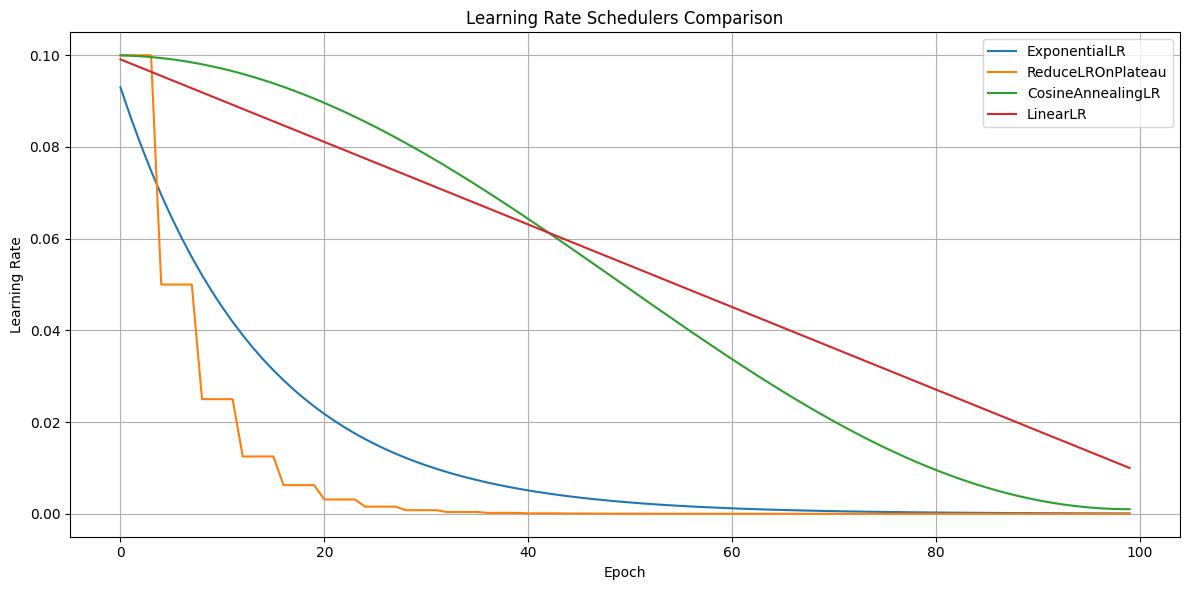

In [29]:
# Визуализация

plt.figure(figsize=(12, 6))
plt.plot(lr_exponential, label="ExponentialLR")
plt.plot(lr_plateau, label="ReduceLROnPlateau")
plt.plot(lr_cosine, label="CosineAnnealingLR")
plt.plot(lr_linear, label="LinearLR")

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedulers Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

<!-- Применим соответствующие `lr_scheduler` для связки `CIFAR10` + `ResNet18`. Дополни функцию `trainer` с обновлением шага раз в эпоху. -->
- Допиши функцию `trainer`, которая задает обучение модели. Шаг `lr_scheduler` должен обновляться раз в эпоху.

In [30]:
def trainer(num_epochs, batch_size, model_class, criterion, optimizer_class=SGD, optimizer_params=None,
            scheduler_class=None, scheduler_params=None, dataset=None,
            device='cuda' if torch.cuda.is_available() else 'cpu'):
    """
    Универсальная функция для обучения моделей PyTorch.

    Параметры:
        num_epochs (int): Количество эпох обучения
        batch_size (int): Размер батча для DataLoader
        model_class (nn.Module): Класс модели
        criterion (nn.Module): Функция потерь
        optimizer_class (optim.Optimizer): Класс оптимизатора
        optimizer_params (dict): Параметры оптимизатора
        scheduler_class (optim.lr_scheduler): Класс планировщика скорости обучения
        scheduler_params (dict): Параметры планировщика скорости обучения
        dataset (Dataset): Объект датасета
        device (str): Устройство для вычислений

    Возвращает:
        model (nn.Module): Обученная модель
        metrics (dict): Словарь с логами
    """

    # Создаем загрузчики данных
    train_loader = DataLoader(dataset.train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(dataset.test_dataset, batch_size=batch_size, shuffle=False)

    # Инициализируем модель, оптимизатор
    model = model_class.to(device)
    optimizer = optimizer_class(model.parameters(), **(optimizer_params or {}))

    # Инициализируем планировщик
    scheduler = None
    if scheduler_class is not None:
        scheduler = scheduler_class(optimizer, **(scheduler_params or {}))

    # Метрики
    metrics = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
        "learning_rates": []
    }

    def train_epoch(epoch):
        model.train()
        total_loss = 0.0
        correct = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(dim=1)  == y).sum().item()

        n = len(train_loader.dataset)
        return total_loss / n, 100 * correct / n

    def test_epoch(epoch):
        model.eval()
        total_loss = 0.0
        correct = 0

        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)

                logits = model(x)
                loss = criterion(logits, y)

                total_loss += loss.item() * x.size(0)
                correct += (logits.argmax(dim=1) == y).sum().item()

        n = len(test_loader.dataset)
        return total_loss / n, 100 * correct / n

    # Обучение
    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_epoch(epoch)
        test_loss, test_acc = test_epoch(epoch)

        # Шаг планировщика

        # Твой код здесь
        if scheduler is not None:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(test_loss)
            else:
                scheduler.step()

        # Сохраняем метрики
        metrics["train_loss"].append(train_loss)
        metrics["train_acc"].append(train_acc)
        metrics["test_loss"].append(test_loss)
        metrics["test_acc"].append(test_acc)
        metrics["learning_rates"].append(optimizer.param_groups[0]['lr'])

        # Логирование
        elapsed = time.time() - start_time
        print(f"Epoch {epoch + 1} / {num_epochs} | "
              f"LR: {metrics['learning_rates'][-1]:.2e} | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
              f"Time: {elapsed:.2f}s")

    # Возвращаем модель и метрики
    return model, metrics

Посмотрим на работу одного `lr_scheduler`.

In [31]:
resnet = resnet18(weights=None, num_classes=10)

config = {
    'num_epochs': 10,
    'batch_size': 128,
    'model_class': resnet,
    'criterion': nn.CrossEntropyLoss(reduction='mean'),
    'optimizer_class': SGD,
    'optimizer_params': {'lr': 1e-2, 'momentum': 0.8, 'weight_decay': 1e-4},
    'scheduler_class': optim.lr_scheduler.CosineAnnealingLR,
    'scheduler_params': {'T_max': 10, 'eta_min': 0.001},
    'dataset': CIFAR10_dataset,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
}

# Запуск обучения
trained_resnet, metrics = trainer(**config)

Epoch 1 / 10 | LR: 9.78e-03 | Train Loss: 1.5303, Train Acc: 44.48% | Test Loss: 1.2834, Test Acc: 52.86% | Time: 335.98s
Epoch 2 / 10 | LR: 9.14e-03 | Train Loss: 1.1304, Train Acc: 59.75% | Test Loss: 1.1451, Test Acc: 60.33% | Time: 329.92s
Epoch 3 / 10 | LR: 8.15e-03 | Train Loss: 0.9109, Train Acc: 67.70% | Test Loss: 1.0516, Test Acc: 64.04% | Time: 329.46s
Epoch 4 / 10 | LR: 6.89e-03 | Train Loss: 0.7271, Train Acc: 74.41% | Test Loss: 0.9744, Test Acc: 66.96% | Time: 336.00s
Epoch 5 / 10 | LR: 5.50e-03 | Train Loss: 0.5468, Train Acc: 80.69% | Test Loss: 1.0280, Test Acc: 66.31% | Time: 330.04s
Epoch 6 / 10 | LR: 4.11e-03 | Train Loss: 0.3636, Train Acc: 87.39% | Test Loss: 1.1065, Test Acc: 67.50% | Time: 332.91s
Epoch 7 / 10 | LR: 2.85e-03 | Train Loss: 0.1958, Train Acc: 93.53% | Test Loss: 1.2281, Test Acc: 68.07% | Time: 334.23s
Epoch 8 / 10 | LR: 1.86e-03 | Train Loss: 0.0827, Train Acc: 97.85% | Test Loss: 1.2688, Test Acc: 69.71% | Time: 336.88s
Epoch 9 / 10 | LR: 1.22e

- Построй сравнительные графики функции ошибок и значений метрики для каждого `lr_scheduler`. Используй параметры ниже.

In [ ]:
schedulers = {
    'CosineAnnealingLR': (optim.lr_scheduler.CosineAnnealingLR, {'T_max': 10, 'eta_min': 0.001}),
    'ExponentialLR': (optim.lr_scheduler.ExponentialLR, {'gamma': 0.9}),
    'ReduceLROnPlateau': (optim.lr_scheduler.ReduceLROnPlateau, {'mode': 'min', 'factor': 0.5, 'patience': 2}),
    'LinearLR': (optim.lr_scheduler.LinearLR, {'start_factor': 0.1, 'end_factor': 1.0, 'total_iters': 10}),
}

# Твой код здесь
results = {}

for name, (scheduler_class, scheduler_params) in schedulers.items():
    print(f"Scheduler: {name}")

    torch.manual_seed(42)

    current_config = config.copy()
    current_config['model_class'] = resnet18(weights=None, num_classes=10)
    current_config['scheduler_class'] = scheduler_class
    current_config['scheduler_params'] = scheduler_params

    model, metrics = trainer(**current_config)

    results[name] = metrics

Scheduler: CosineAnnealingLR
Epoch 1 / 10 | LR: 9.78e-03 | Train Loss: 1.5256, Train Acc: 44.76% | Test Loss: 1.3225, Test Acc: 52.87% | Time: 334.92s
Epoch 2 / 10 | LR: 9.14e-03 | Train Loss: 1.1132, Train Acc: 60.33% | Test Loss: 1.1758, Test Acc: 58.38% | Time: 336.32s
Epoch 3 / 10 | LR: 8.15e-03 | Train Loss: 0.8892, Train Acc: 68.27% | Test Loss: 1.0396, Test Acc: 63.65% | Time: 331.21s
Epoch 4 / 10 | LR: 6.89e-03 | Train Loss: 0.7036, Train Acc: 75.00% | Test Loss: 1.0209, Test Acc: 65.24% | Time: 332.70s
Epoch 5 / 10 | LR: 5.50e-03 | Train Loss: 0.5267, Train Acc: 81.26% | Test Loss: 1.0651, Test Acc: 65.82% | Time: 332.30s
Epoch 6 / 10 | LR: 4.11e-03 | Train Loss: 0.3490, Train Acc: 87.91% | Test Loss: 1.0713, Test Acc: 68.59% | Time: 331.57s
Epoch 7 / 10 | LR: 2.85e-03 | Train Loss: 0.1790, Train Acc: 94.18% | Test Loss: 1.1925, Test Acc: 68.51% | Time: 332.40s
Epoch 8 / 10 | LR: 1.86e-03 | Train Loss: 0.0740, Train Acc: 97.96% | Test Loss: 1.2869, Test Acc: 69.79% | Time: 329

In [ ]:
# Твой код здесь
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for name, metrics in results.items():
    epochs = range(1, len(metrics['train_loss']) + 1)

    axes[0, 0].plot(epochs, metrics['train_loss'], label=name)
    axes[0, 1].plot(epochs, metrics['test_loss'], label=name)

    axes[1, 0].plot(epochs, metrics['train_acc'], label=name)
    axes[1, 1].plot(epochs, metrics['test_acc'], label=name)

titles = [
    ['Train Loss', 'Test Loss'],
    ['Train Accuracy', 'Test Accuracy']
]

for i in range(2):
    for j in range(2):
        axes[i, j].set_title(titles[i][j])
        axes[i, j].set_xlabel('Эпоха')
        axes[i, j].grid(True)
        axes[i, j].legend()

plt.tight_layout()
plt.show()

- Какой `lr_scheduler` показал лучший результат?

__Решение__

Посмотрим, чему научилась наша модель на картинках из тестового датасета. Для этого возьми модель, которая достигла лучших показателей на тестовом датасете, и передай ее как параметр в  функцию `show_model_predictions` для визуализации.

In [ ]:
resnet = resnet18(weights=None, num_classes=10)

config = {
    'num_epochs': 10,
    'batch_size': 128,
    'model_class': resnet,
    'criterion': nn.CrossEntropyLoss(reduction='mean'),
    'optimizer_class': SGD,
    'optimizer_params': {'lr': 1e-2, 'momentum': 0.8, 'weight_decay': 1e-4},
    'scheduler_class': ...,
    'scheduler_params': ...,
    'dataset': CIFAR10_dataset,
    'device' : 'cuda',
}

trained_resnet, metrics = trainer(**config)

In [ ]:
def show_model_predictions(model, dataset, num_samples=20, rows=4, cols=5, device='cpu'):
    model.to(device)
    model.eval()

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), size=num_samples, replace=False)

    for i, ax in enumerate(zip(indices, axes)):
        image, label = dataset[i]
        image_tensor = image.unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(image_tensor)
            _, predicted = torch.max(output, 1)

        imshow(image, ax=ax[1], title=f"True: {classes[label]}\nPred: {classes[predicted.item()]}")

    for j in range(num_samples, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
show_model_predictions(
    trained_resnet,
    CIFAR10_dataset.test_dataset,
    num_samples=20,
    rows=4,
    cols=5,
    device='cuda' if torch.cuda.is_available() else 'cpu'
)

#### Задача 2 [5 баллов]

Реализуй две [техники](https://proceedings.neurips.cc/paper_files/paper/2020/file/c8cc6e90ccbff44c9cee23611711cdc4-Paper.pdf) перемешивания (shuffling): __RandomReshuffling__ и __ShuffleOnce__. Шаффлинг может улучшить теоретическую и практическую сходимости алгоритмов.

1. __RandomReshuffling__ — это метод, при котором данные перемешиваются случайным образом в начале каждой эпохи, обеспечивая более равномерное обновление параметров.

2. __ShuffleOnce__ выполняет перемешивание один раз в начале обучения — это снижает вычислительные затраты при сохранении эффективности сходимости.

Допиши классы `RandomReshufflingSampler` и `ShuffleOnceSampler`.

In [ ]:
class RandomReshufflingSampler(torch.utils.data.Sampler):
    def __init__(self, data_source):
        self.data_source = data_source
        self.num_samples = len(data_source)
        self.indices = np.arange(self.num_samples)

    def __iter__(self):
        np.random.shuffle(self.indices)
        return iter(self.indices.tolist())

    def __len__(self):
        return self.num_samples


class ShuffleOnceSampler(torch.utils.data.Sampler):
    def __init__(self, data_source):
        self.data_source = data_source
        self.num_samples = len(data_source)
        self.indices = np.arange(self.num_samples)

        np.random.shuffle(self.indices)

    def __iter__(self):
        return iter(self.indices.tolist())

    def __len__(self):
        return self.num_samples

Функция `shuffled_trainer` — это адаптация `trainer` для использования кастомных сэмплеров. В DataLoader стоит  `shuffle=False`, чтобы убрать встроенное перемешивание. Чтобы применить функцию, укажи в поле `sampler_class` нужный кастомный сэмплер и задай в поле `sampler_params` его параметры.

In [ ]:
def shuffled_trainer(num_epochs, batch_size, model_class, criterion, optimizer_class=SGD,
                     optimizer_params=None, scheduler_class=None, scheduler_params=None, dataset=None,
                     sampler_class=None, sampler_params=None,
                     device='cuda' if torch.cuda.is_available() else 'cpu'):
    """
    Универсальная функция для обучения моделей PyTorch.

    Параметры:
        num_epochs (int): Количество эпох обучения
        batch_size (int): Размер батча для DataLoader
        model_class (nn.Module): Класс модели
        criterion (nn.Module): Функция потерь
        optimizer_class (optim.Optimizer): Класс оптимизатора
        optimizer_params (dict): Параметры оптимизатора
        scheduler_class (optim.lr_scheduler): Класс планировщика скорости обучения
        scheduler_params (dict): Параметры планировщика скорости обучения
        dataset (Dataset): Объект датасета
        sampler_class (utils.data.Sampler): Класс кастомного sampler
        sampler_params (dict) Параметры sampler
        device (str): Устройство для вычислений

    Возвращает:
        model (nn.Module): Обученная модель
        metrics (dict): Словарь с логами
    """

    # Создаем загрузчики данных
    train_loader = DataLoader(
        dataset.train_dataset,
        batch_size=batch_size,
        shuffle=False,  # Используем кастомный sampler вместо shuffle
        sampler=sampler_class(dataset.train_dataset, **(sampler_params or {})) if sampler_class else None
    )
    test_loader = DataLoader(dataset.test_dataset, batch_size=batch_size, shuffle=False)

    # Инициализируем модель, оптимизатор
    model = model_class.to(device)
    optimizer = optimizer_class(model.parameters(), **(optimizer_params or {}))

    # Инициализируем планировщик
    scheduler = None
    if scheduler_class is not None:
        scheduler = scheduler_class(optimizer, **(scheduler_params or {}))

    # Метрики
    metrics = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
        "learning_rates": []
    }

    def train_epoch(epoch):
        model.train()
        total_loss = 0.0
        correct = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(dim=1)  == y).sum().item()

        n = len(train_loader.dataset)
        return total_loss / n, 100 * correct / n

    def test_epoch(epoch):
        model.eval()
        total_loss = 0.0
        correct = 0

        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)

                logits = model(x)
                loss = criterion(logits, y)

                total_loss += loss.item() * x.size(0)
                correct += (logits.argmax(dim=1) == y).sum().item()

        n = len(test_loader.dataset)
        return total_loss / n, 100 * correct / n

    # Обучение
    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_epoch(epoch)
        test_loss, test_acc = test_epoch(epoch)

        # Шаг планировщика

        # Твой код здесь
        if scheduler is not None:
        if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(test_loss)
        else:
            scheduler.step()

        # Сохраняем метрики
        metrics["train_loss"].append(train_loss)
        metrics["train_acc"].append(train_acc)
        metrics["test_loss"].append(test_loss)
        metrics["test_acc"].append(test_acc)
        metrics["learning_rates"].append(optimizer.param_groups[0]['lr'])

        # Логирование
        elapsed = time.time() - start_time
        print(f"Epoch {epoch + 1} / {num_epochs} | "
              f"LR: {metrics['learning_rates'][-1]:.2e} | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
              f"Time: {elapsed:.2f}s")

    # Возвращаем модель и метрики
    return model, metrics

- Запусти обучение без `lr_scheduler` c теми же параметрами, что и в задаче 1, для `RandomReshufflingSampler` и `ShuffleOnceSampler`.

In [ ]:
# Твой код здесь
base_config = {
    'num_epochs': 10,
    'batch_size': 128,
    'criterion': nn.CrossEntropyLoss(reduction='mean'),
    'optimizer_class': SGD,
    'optimizer_params': {'lr': 1e-2, 'momentum': 0.8, 'weight_decay': 1e-4},
    'dataset': CIFAR10_dataset,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
}

samplers = {
    'RandomReshuffling': RandomReshufflingSampler,
    'ShuffleOnce': ShuffleOnceSampler,
}

results = {}

for name, sampler_class in samplers.items():
    torch.manual_seed(42)
    np.random.seed(42)

    _, metrics = shuffled_trainer(
        **base_config,
        model_class=resnet18(weights=None, num_classes=10),
        sampler_class=sampler_class,
    )
    results[f'{name}, без scheduler'] = metrics

- Запусти обучение с любым `lr_scheduler`.

In [ ]:
# Твой код здесь
for name, sampler_class in samplers.items():
    torch.manual_seed(42)
    np.random.seed(42)

    _, metrics = shuffled_trainer(
        **base_config,
        model_class=resnet18(weights=None, num_classes=10),
        sampler_class=sampler_class,
        scheduler_class=optim.lr_scheduler.CosineAnnealingLR,
        scheduler_params={'T_max': 10, 'eta_min': 0.001},
    )
    results[f'{name}, CosineAnnealingLR'] = metrics

- Построй сравнительные графики сходимости.

In [ ]:
# Твой код здесь
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plots = [
    ('train_loss', 'Train Loss', axes[0, 0]),
    ('test_loss', 'Test Loss', axes[0, 1]),
    ('train_acc', 'Train Accuracy', axes[1, 0]),
    ('test_acc', 'Test Accuracy', axes[1, 1]),
]

for key, title, ax in plots:
    for name, metrics in results.items():
        epochs = range(1, len(metrics[key]) + 1)
        ax.plot(epochs, metrics[key], label=name)
    ax.set_title(title)
    ax.set_xlabel('Эпоха')
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

- Какой из шаффлингов дает улучшение?

__Решение__